# Toy task, step 2: responding with the wheel
Oct 2026 \
author: Inês Laranjeira (sketch drafted with Claude)

Notebook 0 showed that an agent that knows the task states (M1) learns the toy task in about 100
trials, roughly 100× faster than mice. Here the response has to be **executed with the wheel**,
to see how much of that gap comes from the motor side.

**What changes compared with notebook 0**
* **Each bout moves the stimulus.** The displacement is random (lognormal around a mean amplitude),
  and with some probability part of the bout swings back the other way (a reversal, the wiggle).
* **The response is a threshold crossing.** Reaching +1 (threshold units) toward the stimulus side is
  correct; reaching −1 the other way is an error. In between the trial continues, so a response
  can take many bouts.
* **The stimulus position is visible to the agent** (5 position bins per side), as it is on screen
  for the mouse.
* **The response window is 60 s** (600 bins), roughly as on the rig. No response by then is a
  timeout, which counts as not correct.
* **Eligibility traces are optional** (λ). With λ = 0 the reward updates only the last bout; with
  λ = 0.8 it also reaches the bouts just before it.

**Unchanged:** M1's state for no-stimulus time (two clocks), actions (wait / left bout / right bout,
3 bins each), learning rule, one contrast.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import toy_task as tt

INK, MUTED = '#1d1d1b', '#6b6b66'
EPOCH_COL = ['#efefed', '#d6d6d2', '#b4b4ae']
EPOCH_NAME = ['ITI', 'quiescence', 'stimulus']
MOTOR_COL = {'expert': '#2a78d6', 'naive': '#eb6834', 'improving': '#1baf7a'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'font.size': 10, 'axes.titlesize': 11, 'lines.linewidth': 2})
WHEEL = dict(wheel=True, resp_window=600)
NAIVE_AMP = 0.1     # mean bout amplitude of the naive motor, in threshold units (~10 bouts to respond)

def ttc(b):
    return tt.trials_to_criterion(b.accuracy.values, b.trial.values)

## What a wheel response looks like
The same M1 agent with a naive motor (mean bout amplitude 0.1, reversal probability 0.35). The
upper panel of each pair shows the epochs and bout onsets; the lower panel shows where the
stimulus is during the stimulus epoch. The dashed lines are the correct (+1) and error (−1)
thresholds, drawn in the direction of the stimulus side.

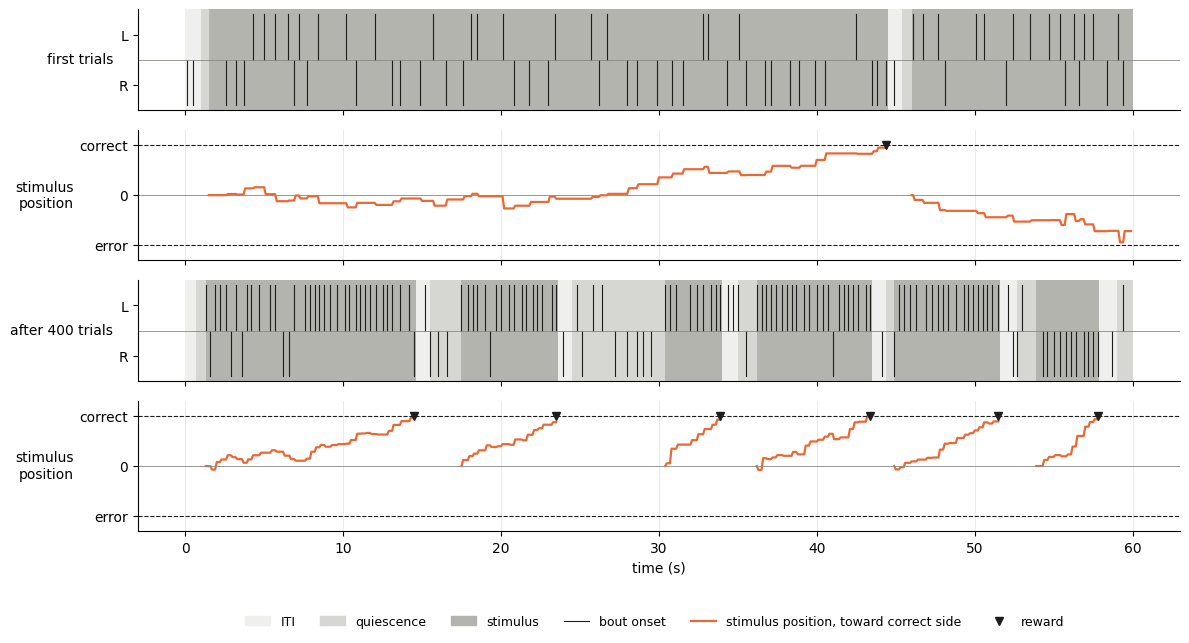

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(12, 6.2), sharex=True,
                         gridspec_kw=dict(height_ratios=[1, 1.3, 1, 1.3]))
W = 600   # 60 s
for r, (lo, title) in enumerate([(0, 'first trials'), (400, 'after 400 trials')]):
    _, _, tr = tt.run('M1', n_trials=lo + 30, seed=1, record=(lo, lo + 30),
                      motor='naive', naive_amp=NAIVE_AMP, **WHEEL)
    tr = tr[:W]; tt_ = np.arange(len(tr)) * tt.DT
    ax = axes[2 * r]; ax.grid(False)
    for i, ph in enumerate(tr[:, 1].astype(int)):
        ax.axvspan(tt_[i], tt_[i] + tt.DT, color=EPOCH_COL[ph], lw=0)
    for i in np.flatnonzero(tr[:, 2] > 0):
        y0, y1 = (0.5, 0.95) if tr[i, 2] == 1 else (0.05, 0.5)
        ax.plot([tt_[i]] * 2, [y0, y1], color=INK, lw=0.8)
    ax.axhline(0.5, color='#8a8a85', lw=0.6)
    ax.set_yticks([0.25, 0.75]); ax.set_yticklabels(['R', 'L']); ax.set_ylim(0, 1)
    ax.set_ylabel(title, rotation=0, ha='right', va='center')
    ax = axes[2 * r + 1]
    stim_side = np.zeros(len(tr))
    cur = 0
    for i in range(len(tr)):            # carry the side through the stimulus epoch
        if tr[i, 1] == 2 and tr[i, 3] > 0: cur = tr[i, 3]
        if tr[i, 1] != 2: cur = 0
        stim_side[i] = cur
    target = np.where(stim_side == 1, -1, 1)
    prog = np.where(stim_side > 0, tr[:, 5] * target, np.nan)   # progress toward the correct side
    ax.plot(tt_, prog, color='#eb6834', lw=1.6)
    for i in np.flatnonzero(tr[:, 4] > 0):
        ax.plot(tt_[i], 1, marker='v', color=INK, ms=6)
    ax.axhline(1, color=INK, lw=0.8, ls='--'); ax.axhline(-1, color=INK, lw=0.8, ls='--')
    ax.axhline(0, color='#8a8a85', lw=0.6)
    ax.set_ylim(-1.3, 1.3); ax.set_yticks([-1, 0, 1]); ax.set_yticklabels(['error', '0', 'correct'])
    ax.set_ylabel('stimulus\nposition', rotation=0, ha='right', va='center')
axes[-1].set_xlabel('time (s)')
handles = [Patch(color=EPOCH_COL[i], label=EPOCH_NAME[i]) for i in range(3)] + \
          [Line2D([], [], color=INK, lw=0.8, label='bout onset'),
           Line2D([], [], color='#eb6834', lw=1.6, label='stimulus position, toward correct side'),
           Line2D([], [], color=INK, marker='v', ls='', label='reward')]
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.55, -0.04), fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

## How small do movements have to be to slow learning?
Sweep of the mean bout amplitude with a fixed motor (reversal probability 0.35), λ = 0, 4 seeds.
An amplitude of 1.2 crosses the threshold in about one bout; 0.1 needs about 10 bouts in the same
direction.

never reached 80% in 2500 trials: {0.05: 0, 0.07: 0, 0.1: 0, 0.2: 0, 0.4: 0, 1.2: 0}


,ttc,bouts_first,rt_first,timeout_first,tpm_first
amp,,,,,
0.05,1250.0,79.34,59.05,0.94,0.98
0.07,175.0,73.88,53.34,0.65,1.08
0.10,100.0,55.23,37.91,0.31,1.49
0.20,100.0,17.81,11.44,0.00,4.38
0.40,100.0,6.70,4.17,0.00,8.96
1.20,75.0,1.73,0.86,0.00,18.26


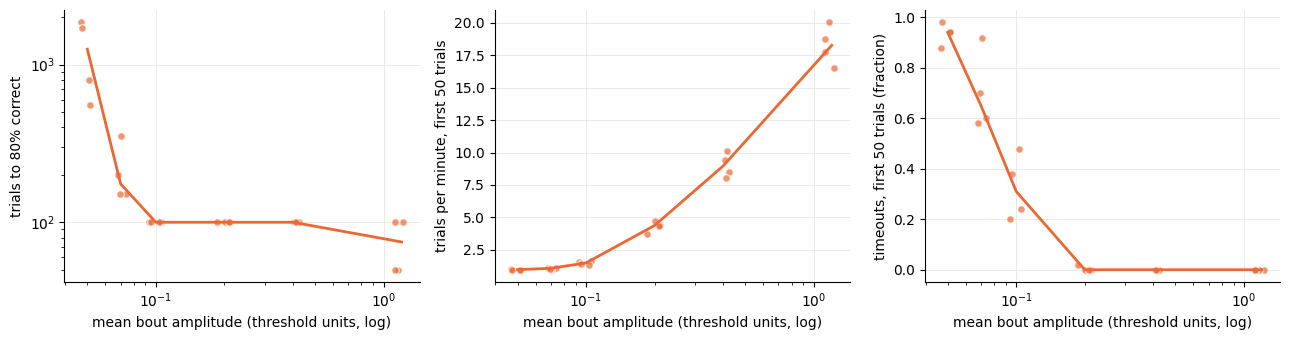

In [3]:
AMPS = [1.2, 0.4, 0.2, 0.1, 0.07, 0.05]
rows = []
for amp in AMPS:
    for s in range(4):
        b = pd.DataFrame(tt.run('M1', n_trials=2500, seed=s, motor='naive', naive_amp=amp, **WHEEL)[0])
        first = b.iloc[0]
        rows.append(dict(amp=amp, seed=s, ttc=ttc(b), rt_first=first.rt_s, timeout_first=first.timeout_frac,
                         tpm_first=first.trials_per_min, bouts_first=first.bouts_per_response))
amp_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
jit = np.random.default_rng(0).uniform(0.93, 1.07, len(amp_df))
for ax, col, lab in zip(axes, ['ttc', 'tpm_first', 'timeout_first'],
                        ['trials to 80% correct', 'trials per minute, first 50 trials',
                         'timeouts, first 50 trials (fraction)']):
    ax.scatter(amp_df.amp * jit, amp_df[col], s=30, color='#eb6834', alpha=0.7, edgecolor='white', linewidth=1)
    med = amp_df.groupby('amp')[col].median()
    ax.plot(med.index, med.values, color='#eb6834')
    ax.set_xscale('log'); ax.set_xlabel('mean bout amplitude (threshold units, log)'); ax.set_ylabel(lab)
axes[0].set_yscale('log')
fig.tight_layout()
print('never reached 80% in 2500 trials:', amp_df.ttc.isna().groupby(amp_df.amp).sum().to_dict())
amp_df.groupby('amp')[['ttc', 'bouts_first', 'rt_first', 'timeout_first', 'tpm_first']].median().round(2)

## Expert, naive and improving motor
* **Expert**: mean amplitude 1.2, no reversals.
* **Naive**: mean amplitude 0.1, reversal probability 0.35, fixed.
* **Improving**: starts naive and moves toward expert as bouts accumulate
  (half-way after about 2,000 bouts).

4 seeds each, λ = 0.

motor
expert        75.0
naive        100.0
improving    100.0
Name: median trials to 80%, dtype: float64

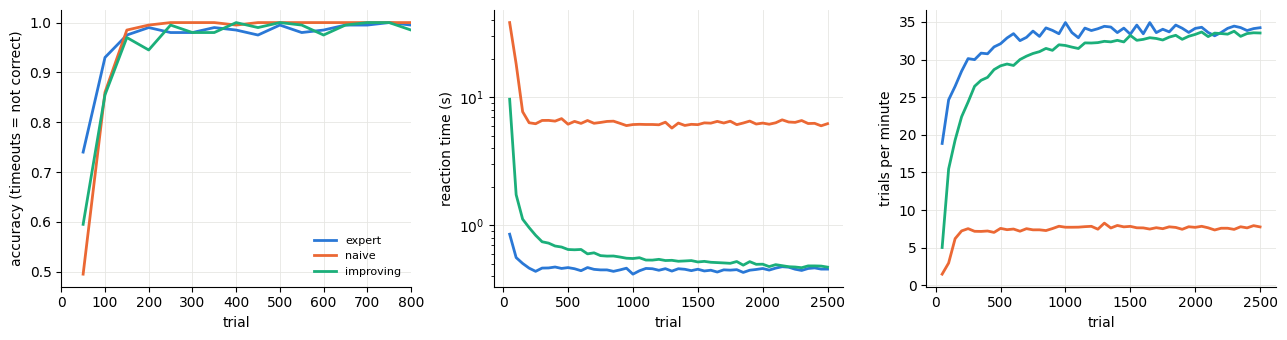

In [4]:
rows = []
for motor in ['expert', 'naive', 'improving']:
    for s in range(4):
        rows += [dict(r, motor=motor) for r in
                 tt.run('M1', n_trials=2500, seed=s, motor=motor, naive_amp=NAIVE_AMP, **WHEEL)[0]]
mot = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for motor, g in mot.groupby('motor', sort=False):
    m = g.groupby('trial')[['accuracy', 'rt_s', 'trials_per_min']].mean()
    for ax, col in zip(axes, ['accuracy', 'rt_s', 'trials_per_min']):
        ax.plot(m.index, m[col], color=MOTOR_COL[motor], label=motor)
axes[0].set_ylabel('accuracy (timeouts = not correct)'); axes[0].set_xlim(0, 800)
axes[1].set_ylabel('reaction time (s)'); axes[1].set_yscale('log')
axes[2].set_ylabel('trials per minute')
for ax in axes: ax.set_xlabel('trial')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
mot.groupby(['motor', 'seed'], sort=False).apply(ttc, include_groups=False).groupby('motor', sort=False).median().rename('median trials to 80%')

## Eligibility traces: λ = 0 vs λ = 0.8
Naive motor at two amplitudes, 3 seeds. With many bouts per response, TD(0) passes credit back one
bout per visit; traces pass it to recent bouts immediately.

In [5]:
rows = []
for amp in [0.1, 0.07]:
    for lam_ in [0.0, 0.8]:
        for s in range(3):
            b = pd.DataFrame(tt.run('M1', n_trials=1500, seed=s, motor='naive', naive_amp=amp,
                                    trace_lambda=lam_, **WHEEL)[0])
            rows.append(dict(amp=amp, trace_lambda=lam_, seed=s, ttc=ttc(b)))
lam_df = pd.DataFrame(rows)
lam_df.pivot_table(index='amp', columns='trace_lambda', values='ttc', aggfunc=['median', 'min', 'max'])

median         min       max     
trace_lambda    0.0    0.8  0.0  0.8  0.0  0.8
amp                                           
0.07          200.0  100.0  150  100  350  200
0.10          100.0  100.0  100  100  100  100

## Observations
* **Responding with the wheel barely changes how many trials learning takes.** Above a mean
  bout amplitude of about 0.1 of the threshold, the agent reaches 80% correct in 75–100 trials,
  the same as in notebook 0. That holds even at amplitude 0.1 with reversals, where the first
  responses take about 55 bouts and 38 s.
* **Bad execution costs time, not trials.** Trials per minute fall from about 18 in the first
  50 trials with expert movements to about 1.5 with naive ones. Per trial, the agent learns just
  as fast.
* **Learning slows only when most trials time out.** At amplitude 0.05, 94% of the first trials time
  out and the agent needs a median of 1,250 trials (550–1,850). It gets reward so rarely that
  there is little to learn from. At 0.07 it needs about 175.
* **Reversals hardly matter here.** The agent sees the stimulus position, so a wrong swing is
  corrected by later bouts. An error requires a *net* wrong displacement of a full threshold.
* **Improving vs fixed motor:** same trials to criterion (about 100). The improving motor's
  reaction time falls gradually, from about 10 s to 0.5 s over 2,500 trials, long after choice
  learning is done. In this toy, motor improvement and choice learning are separate processes.
* **Eligibility traces help only in the slowest regime.** At amplitude 0.1, λ = 0.8 makes no
  difference (100 vs 100 trials); at 0.07, it halves the median (200 → 100).

**Implications**
* In this toy, the motor side cannot explain the ~100× gap between M1 and the mice, *unless*
  early mice time out on most trials. **They don't.** In the local training files (102 mice),
  the median timeout fraction is 0.4% on training day 1 (75th percentile 2.8%), and the median
  reaction time is about 4.2 s on day 1, falling to about 1.5 s by day 5. That matches the toy's
  amplitude 0.2–0.4 range, where learning takes about 100 trials. (This check was run outside
  the notebook; `choice == 0` is a timeout.)
* Motor quality shows up in **reaction time and trials per minute**. So it could still matter for
  learning measured in **sessions** (fewer trials per session) without mattering for learning
  measured in **trials**, which is the same distinction as in the "activity → faster learning"
  question.
* The gap now has to be explained by something other than execution: discovering the task states,
  a much lower learning rate, or something not yet in the toy, such as engagement or bias.